# AGHRI 3D tracking: paper tables and figures

This notebook analyses LiDAR-only 3D human tracking on the six held-out AGHRI test sequences, which cover footpath, strawberry polytunnel, and vineyard settings. The detector-based results use the PointPillars scratch checkpoint selected on the AGHRI validation split. Results using the SECOND scratch checkpoint are kept separately in `reports/heldout/test/second_scratch/`.

Two detection inputs are evaluated:

- **Ground-truth-based (GT oracle)** — annotated 3D bounding boxes are supplied as detections, with participant identities withheld from the trackers. This setting helps isolate tracking errors from detector errors.
- **PointPillars detector-based** — scored 3D person detections from the AGHRI-trained PointPillars model are supplied to the trackers.

Three trackers are compared under both input settings:

- **AB3DMOT** — Kalman filtering and Hungarian assignment using oriented BEV IoU.
- **CenterPoint tracker** — velocity-based centre-distance association without a Kalman filter.
- **SimpleTrack** — two-stage association that separates high- and low-confidence detections.

The five revised manuscript figures are included in `notebooks/figures/` and displayed in the matching sections below. The tables and figure-source values are read from the saved evaluation CSVs. Run this notebook from `3d-tracking` or its `notebooks` directory.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image


def find_root():
    override = os.environ.get("AGHRI_3D_TRACK_ROOT")
    if override:
        return Path(override).expanduser().resolve()
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "reports/heldout/test/pointpillars_scratch/summary.csv").exists():
            return candidate
        if (candidate / "3d-tracking/reports/heldout/test/pointpillars_scratch/summary.csv").exists():
            return candidate / "3d-tracking"
    raise FileNotFoundError("Run from 3d-tracking or set AGHRI_3D_TRACK_ROOT")

ROOT = find_root()
DATA = ROOT / "reports/heldout/test/pointpillars_scratch"
FIGURES = ROOT / "notebooks/figures"
summary = pd.read_csv(DATA / "summary.csv")
sequence = pd.read_csv(DATA / "per_sequence.csv")
macro = summary.loc[summary.aggregation == "macro"].copy()
pooled = summary.loc[summary.aggregation == "pooled"].copy()

TRACKERS = {"ab3dmot": "AB3DMOT", "centerpoint": "CenterPoint", "simpletrack": "SimpleTrack"}
INPUTS = {"gt": "Ground-truth-based", "pointpillars_scratch": "Detector-based"}
assert len(macro) == len(pooled) == 6
assert len(sequence) == 36
assert set(macro.frames) == {1308} and set(macro.sequences) == {6}
assert set(sequence.sequence) == set((ROOT / "reports/heldout/split_lists/test.txt").read_text().splitlines())

def show_figure(filename):
    path = FIGURES / filename
    if not path.exists():
        raise FileNotFoundError(path)
    display(Image(filename=str(path)))

print("Loaded six held-out sequences, three trackers, and two input settings.")

Loaded six held-out sequences, three trackers, and two input settings.


## Overall LiDAR-only tracking performance

The paper's overall table uses the `macro` rows: MOTA, MOTP, IDF1, HOTA, DetA, AssA, and recall are equal means of six sequence-level scores. Identity switches are summed. `motp_iou` is mean matched oriented-BEV IoU, so higher is better. The separate pooled rows are retained in the report CSV and are not used for this table.

In [2]:
cols = ["source", "tracker", "mota", "motp_iou", "idf1", "hota", "deta", "assa", "recall", "num_switches"]
overall = macro[cols].copy()
overall["Input setting"] = overall.source.map(INPUTS)
overall["Tracker"] = overall.tracker.map(TRACKERS)
overall = overall.rename(columns={"mota": "MOTA", "motp_iou": "MOTP", "idf1": "IDF1", "hota": "HOTA", "deta": "DetA", "assa": "AssA", "recall": "Recall", "num_switches": "IDSW"})
overall = overall[["Input setting", "Tracker", "MOTA", "MOTP", "IDF1", "HOTA", "DetA", "AssA", "Recall", "IDSW"]]
overall = overall.set_index(["Input setting", "Tracker"]).reindex(pd.MultiIndex.from_product([list(INPUTS.values()), list(TRACKERS.values())], names=["Input setting", "Tracker"]))
display(overall.round(4))
assert round(overall.loc[("Detector-based", "CenterPoint"), "MOTA"], 4) == 0.8709
assert round(overall.loc[("Ground-truth-based", "CenterPoint"), "HOTA"], 4) == 0.8895

MOTA    MOTP    IDF1    HOTA    DetA  \
Input setting      Tracker                                               
Ground-truth-based AB3DMOT      0.9399  0.9322  0.6517  0.7068  0.8928   
                   CenterPoint  0.9758  1.0000  0.8590  0.8895  0.9798   
                   SimpleTrack  0.9661  0.9326  0.7206  0.7553  0.9166   
Detector-based     AB3DMOT      0.8510  0.6667  0.5296  0.4495  0.5539   
                   CenterPoint  0.8709  0.6598  0.6803  0.5265  0.5546   
                   SimpleTrack  0.8550  0.6677  0.6560  0.5183  0.5522   

                                  AssA  Recall  IDSW  
Input setting      Tracker                            
Ground-truth-based AB3DMOT      0.5912  0.9755    28  
                   CenterPoint  0.8187  0.9918    15  
                   SimpleTrack  0.6477  1.0000    31  
Detector-based     AB3DMOT      0.4886  0.8884    41  
                   CenterPoint  0.6406  0.8984    36  
                   SimpleTrack  0.6207  0.8893    20

### Overall MOTA, IDF1, and HOTA


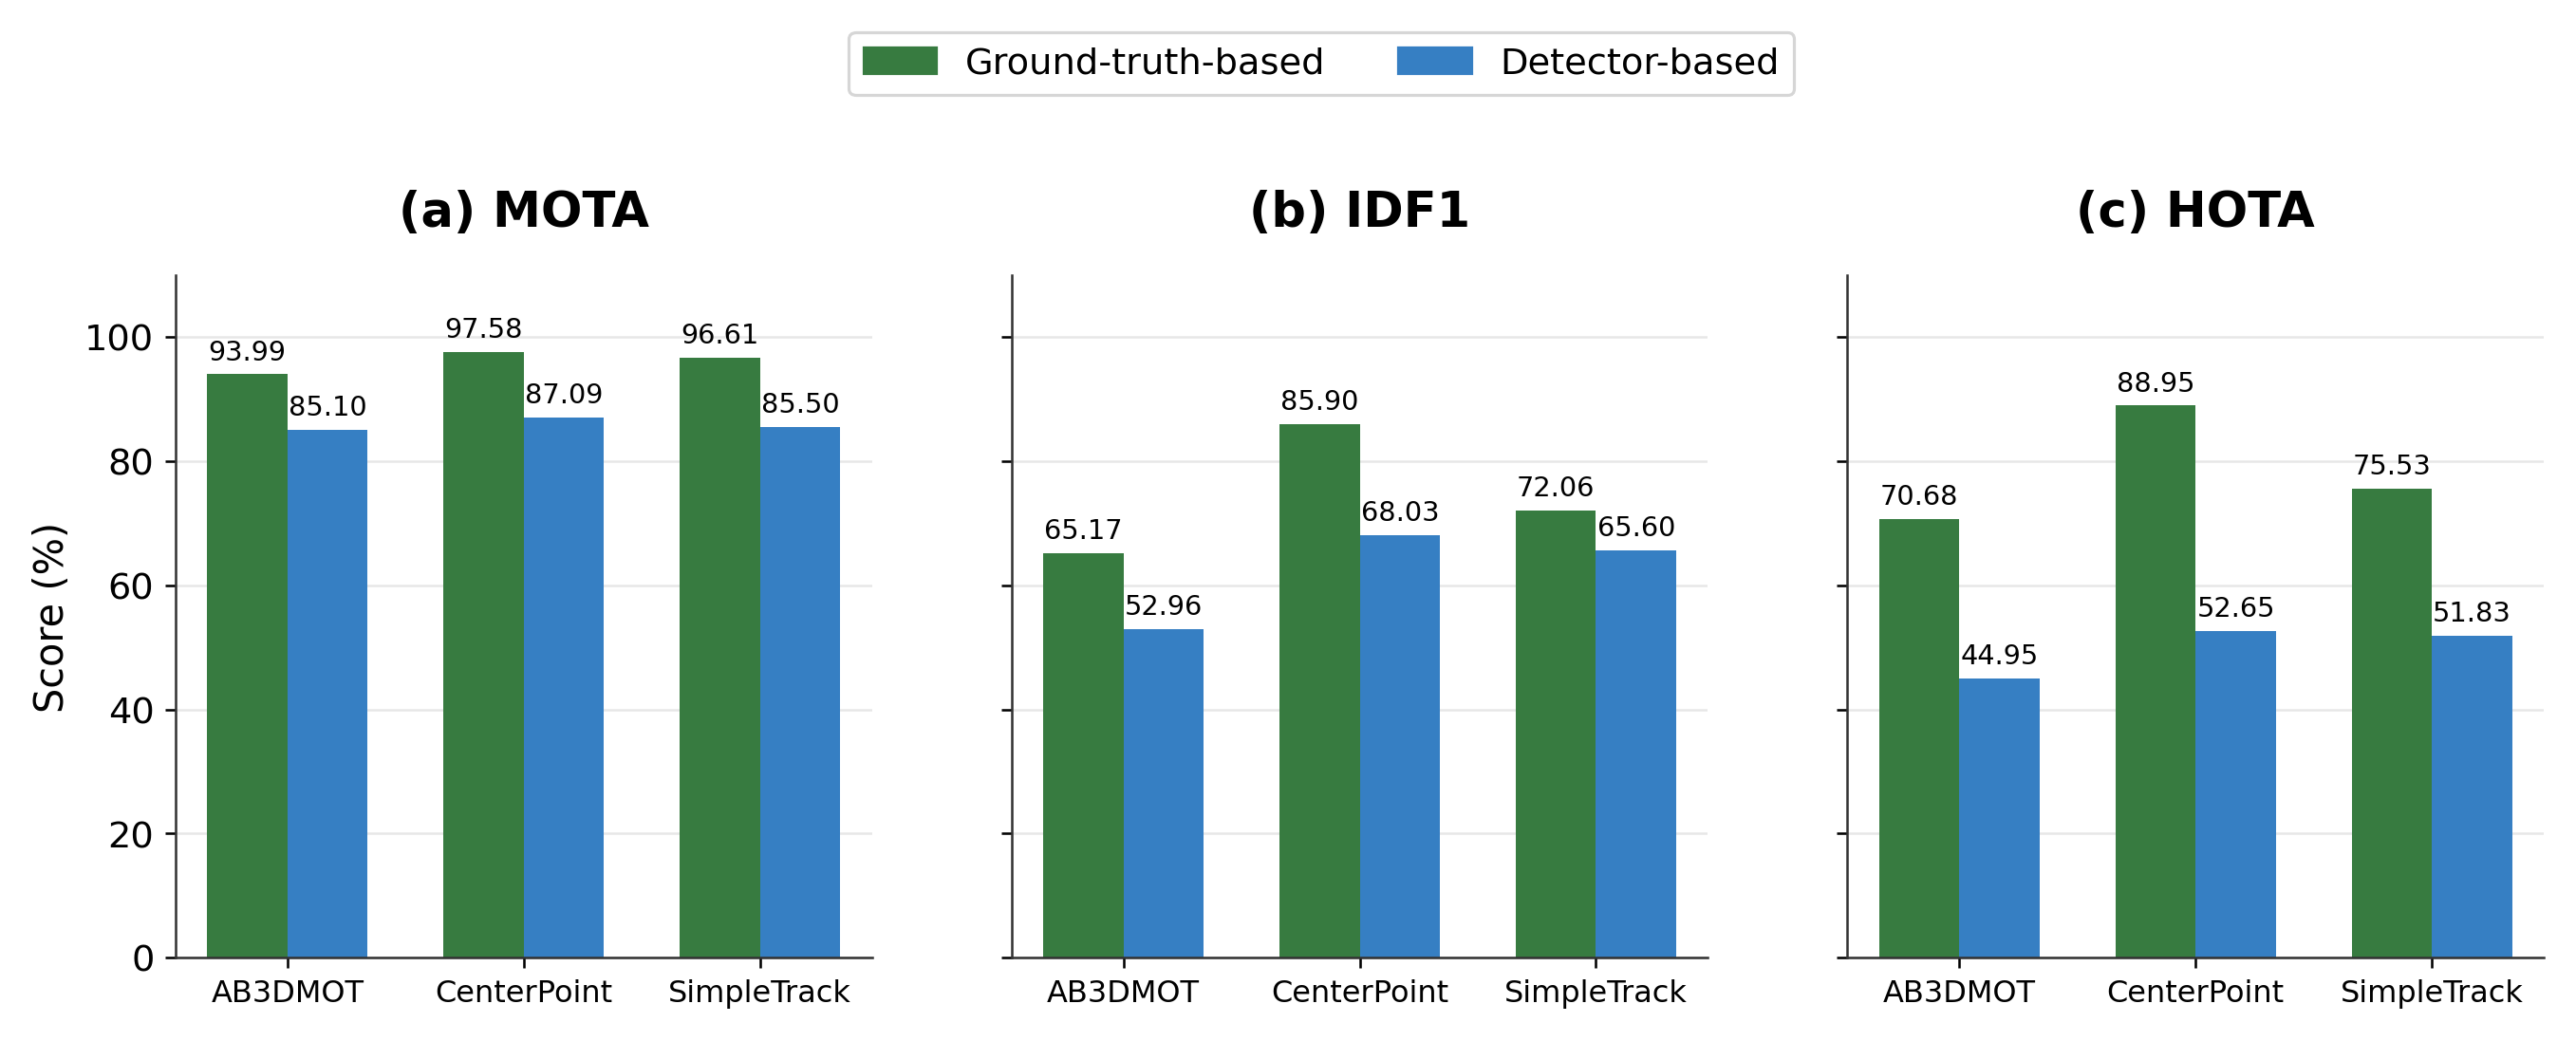

In [3]:
show_figure("aghri_3d_tracking_overall_comparison_new.png")

## Effect of detection quality across sequences

The following two figures show three *selected* test sequences for discussion: footpath, inside strawberry polytunnel, and outside vineyard. They are illustrative; the overall table above uses all six held-out sequences. The sequence-level bars each correspond to one tracker on one LiDAR sequence.

In [4]:
selected = {
    "Footpath": "footpath1_p1_oj+mk+gl_1walk+check_st_11_12_2024_1_label",
    "Inside strawberry polytunnel": "in_straw_3pick_diff_st_10_24_2024_5_a_label",
    "Outside vineyard": "out_vine_4swap+walk_st_ly_11_06_2024_2_label",
}
participants = {"Footpath": 1, "Inside strawberry polytunnel": 3, "Outside vineyard": 4}
composition = pd.DataFrame([
    {"Sequence": label, "Frames": int(sequence.loc[sequence.sequence == name, "num_frames"].iloc[0]), "Participant identities": participants[label]}
    for label, name in selected.items()
])
assert composition.Frames.tolist() == [200, 126, 276]
display(composition)

,Sequence,Frames,Participant identities
0,Footpath,200,1
1,Inside strawberry polytunnel,126,3
2,Outside vineyard,276,4


### Composition of the three selected sequences


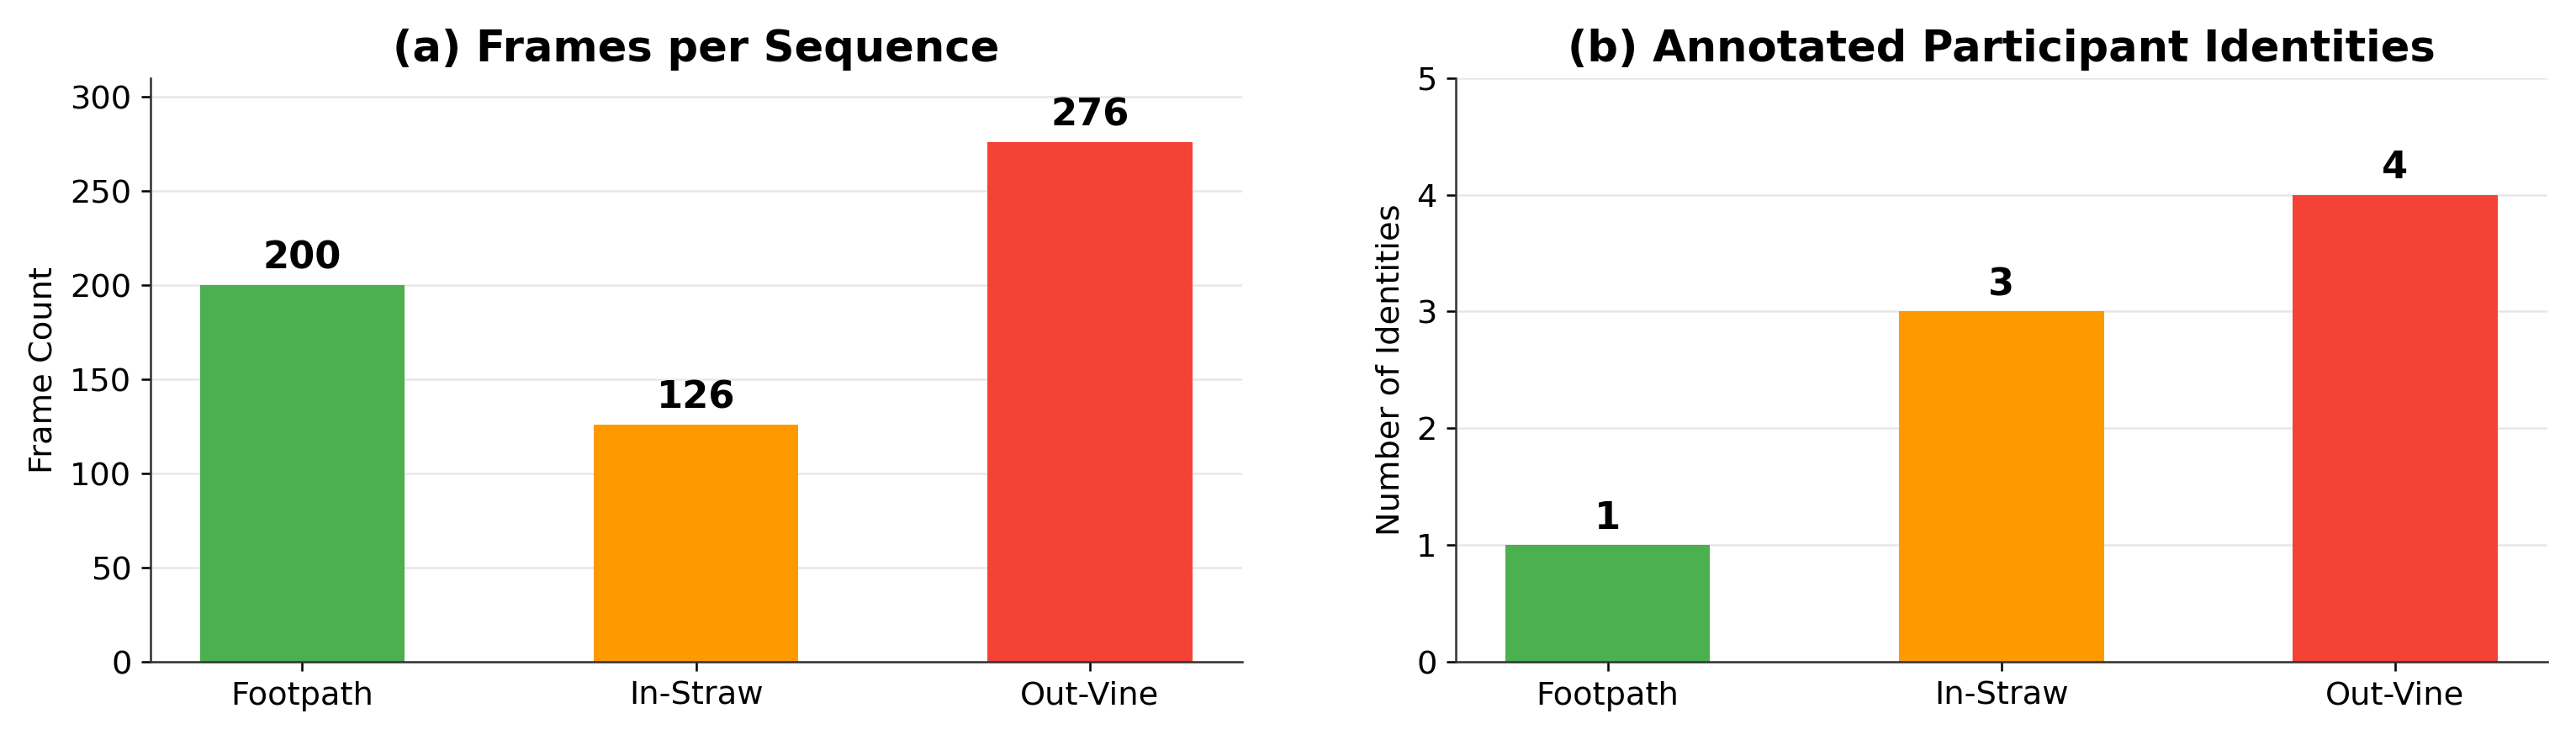

In [5]:
show_figure("aghri_3d_tracking_scenario_composition_new.png")

### Sequence-level MOTA, IDF1, and HOTA

The ground-truth-based control supplies annotated 3D boxes without participant IDs. The detector-based setting uses scored PointPillars detections. Values below are proportions; the figure displays percentages.


,Sequence,Input setting,Tracker,mota,idf1,hota
1,Footpath,Ground-truth-based,AB3DMOT,0.8650,0.2864,0.4211
2,Inside strawberry polytunnel,Ground-truth-based,AB3DMOT,0.9735,0.8757,0.8610
5,Outside vineyard,Ground-truth-based,AB3DMOT,0.9392,0.5794,0.6939
7,Footpath,Ground-truth-based,CenterPoint,1.0000,1.0000,1.0000
8,Inside strawberry polytunnel,Ground-truth-based,CenterPoint,1.0000,1.0000,1.0000
11,Outside vineyard,Ground-truth-based,CenterPoint,0.9432,0.5794,0.7041
13,Footpath,Ground-truth-based,SimpleTrack,0.9350,0.4275,0.5112
14,Inside strawberry polytunnel,Ground-truth-based,SimpleTrack,0.9841,0.8711,0.8601
17,Outside vineyard,Ground-truth-based,SimpleTrack,0.9621,0.5765,0.6958
19,Footpath,Detector-based,AB3DMOT,0.9150,0.3518,0.3770


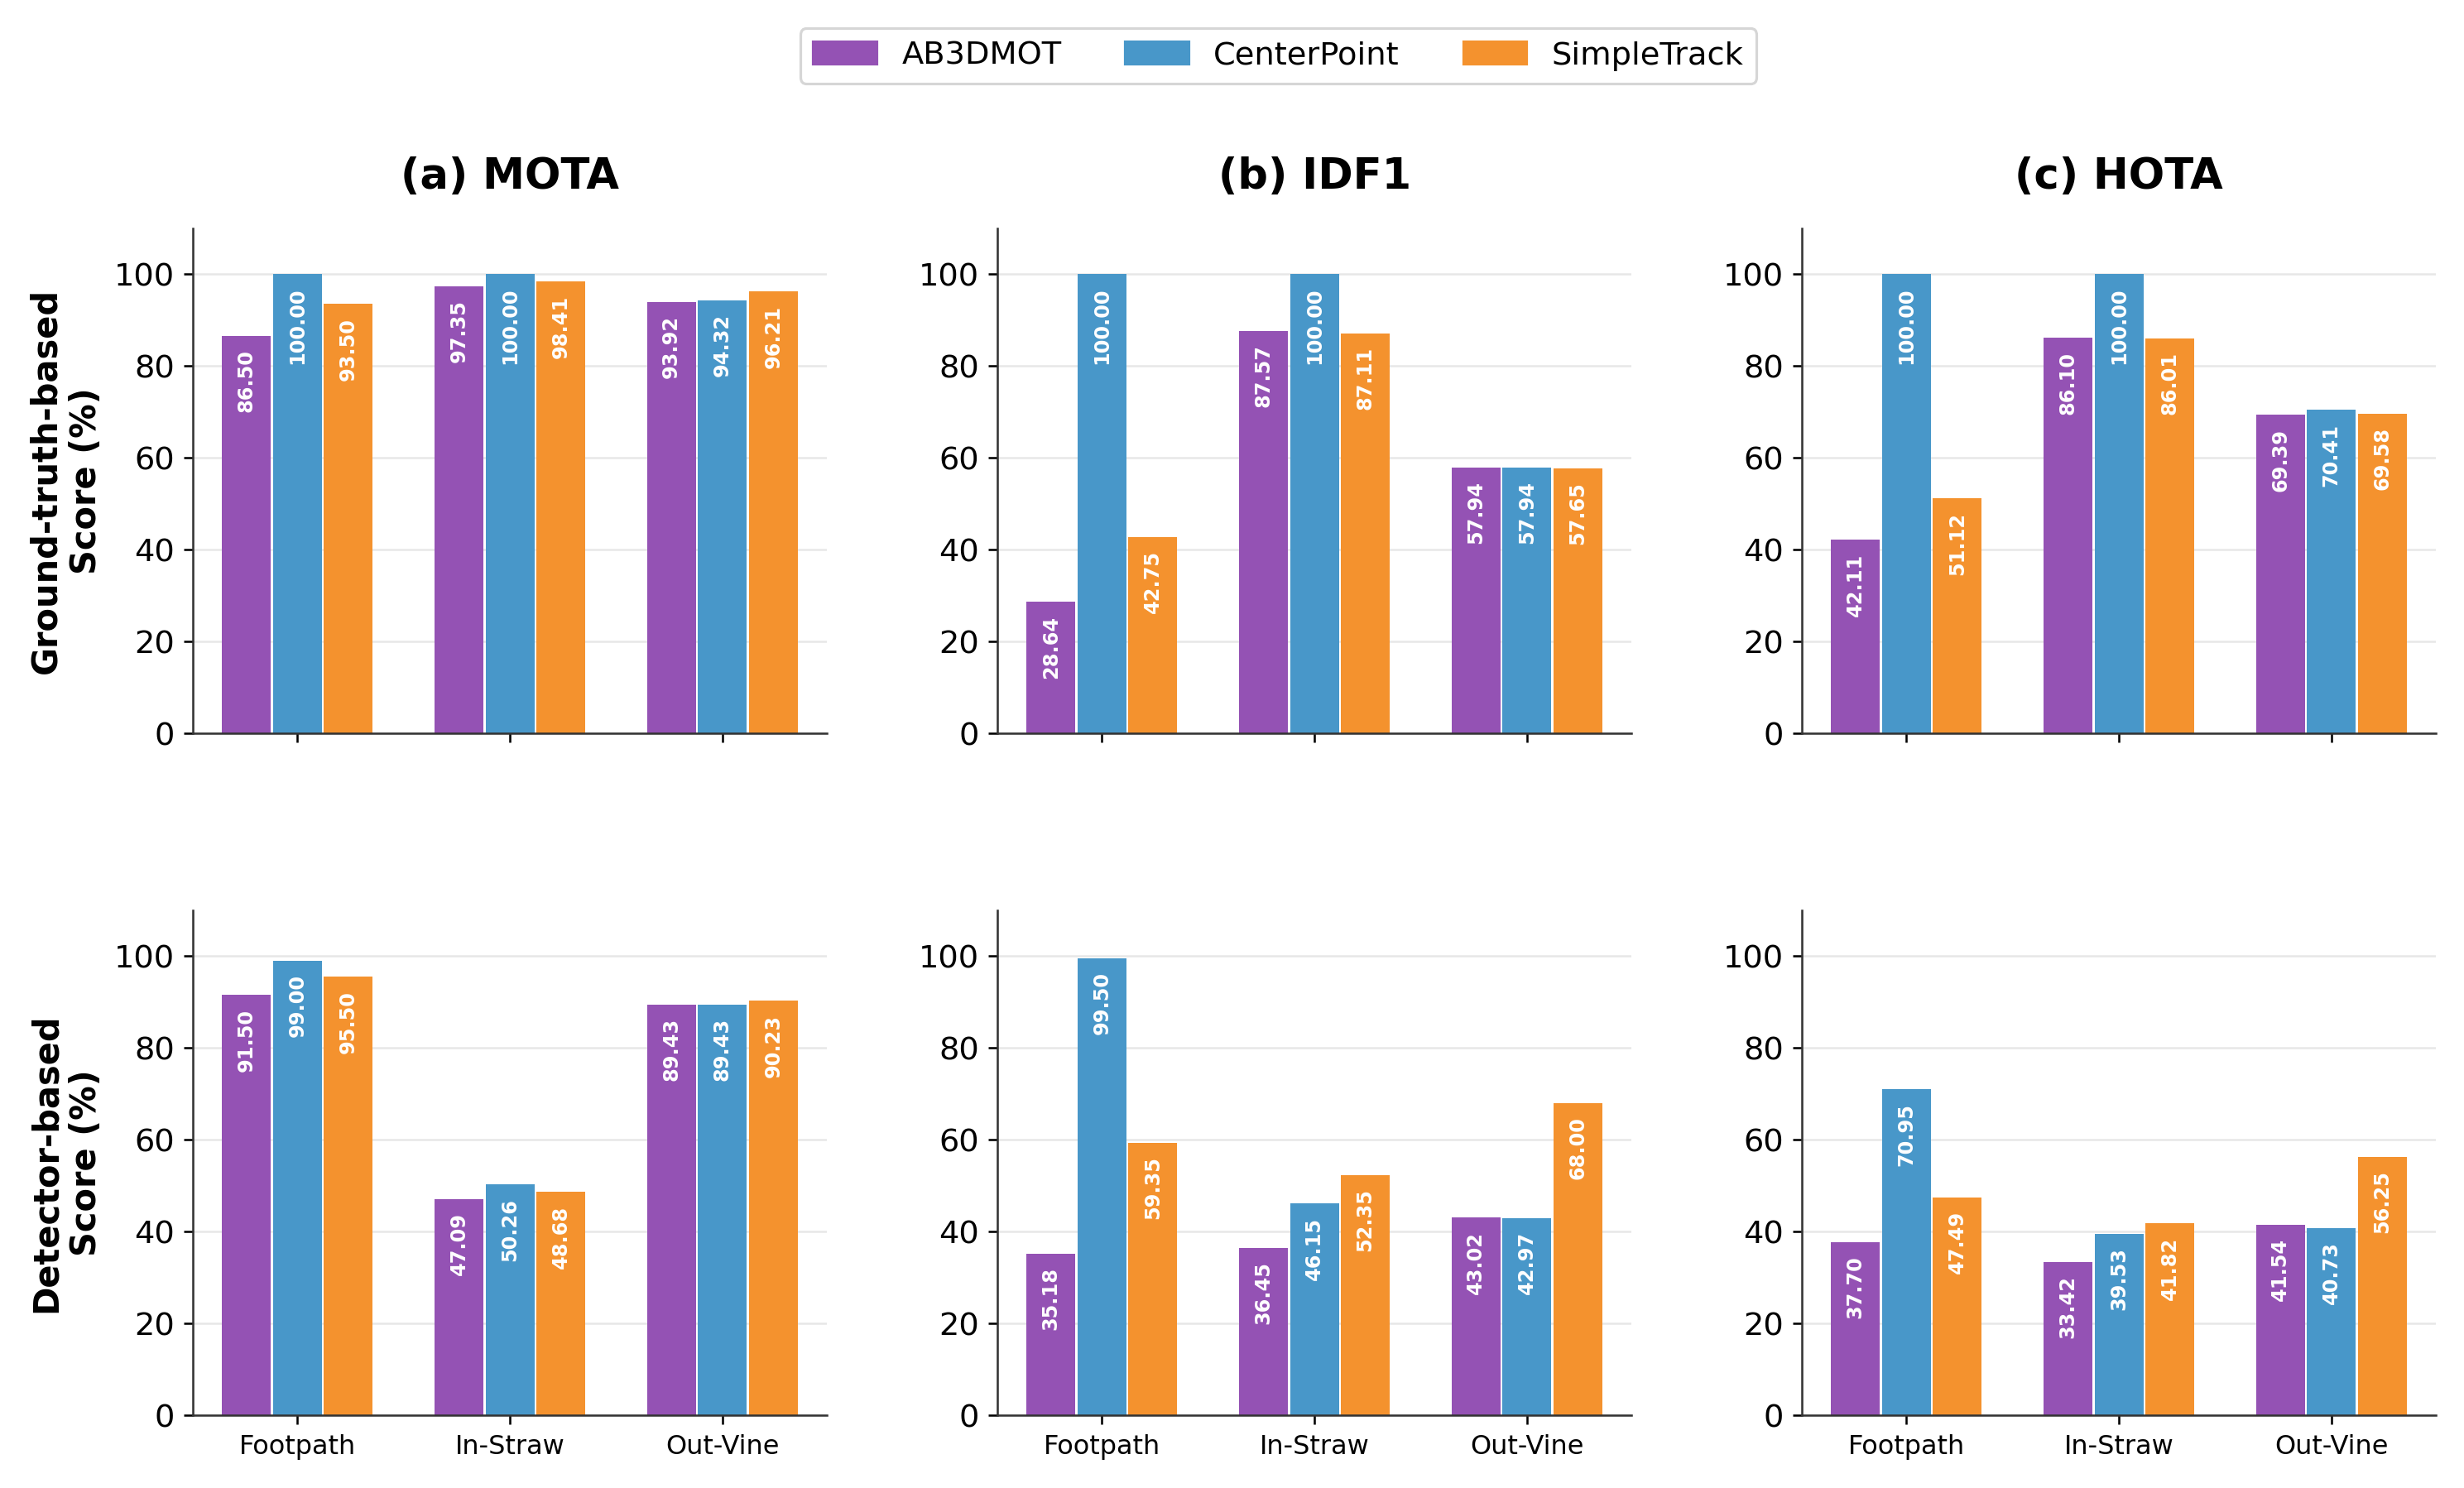

In [6]:
selected_rows = sequence.loc[sequence.sequence.isin(selected.values()), ["sequence", "source", "tracker", "mota", "idf1", "hota"]].copy()
selected_rows["Sequence"] = selected_rows.sequence.map({v: k for k, v in selected.items()})
selected_rows["Input setting"] = selected_rows.source.map(INPUTS)
selected_rows["Tracker"] = selected_rows.tracker.map(TRACKERS)
selected_rows = selected_rows[["Sequence", "Input setting", "Tracker", "mota", "idf1", "hota"]]
assert len(selected_rows) == 18
display(selected_rows.round(4))
show_figure("aghri_3d_tracking_detection_quality_across_scenarios_new.png")

## Detection and association components

The figure places equal-sequence DetA and AssA values from the overall table in separate panels for ground-truth-based and detector-based input. The diagonal marks equal DetA and AssA. These components are reported as macro values; the pooled summary does not contain pooled HOTA-family scores.


DetA    AssA    HOTA
Input setting      Tracker                            
Ground-truth-based AB3DMOT      0.8928  0.5912  0.7068
                   CenterPoint  0.9798  0.8187  0.8895
                   SimpleTrack  0.9166  0.6477  0.7553
Detector-based     AB3DMOT      0.5539  0.4886  0.4495
                   CenterPoint  0.5546  0.6406  0.5265
                   SimpleTrack  0.5522  0.6207  0.5183

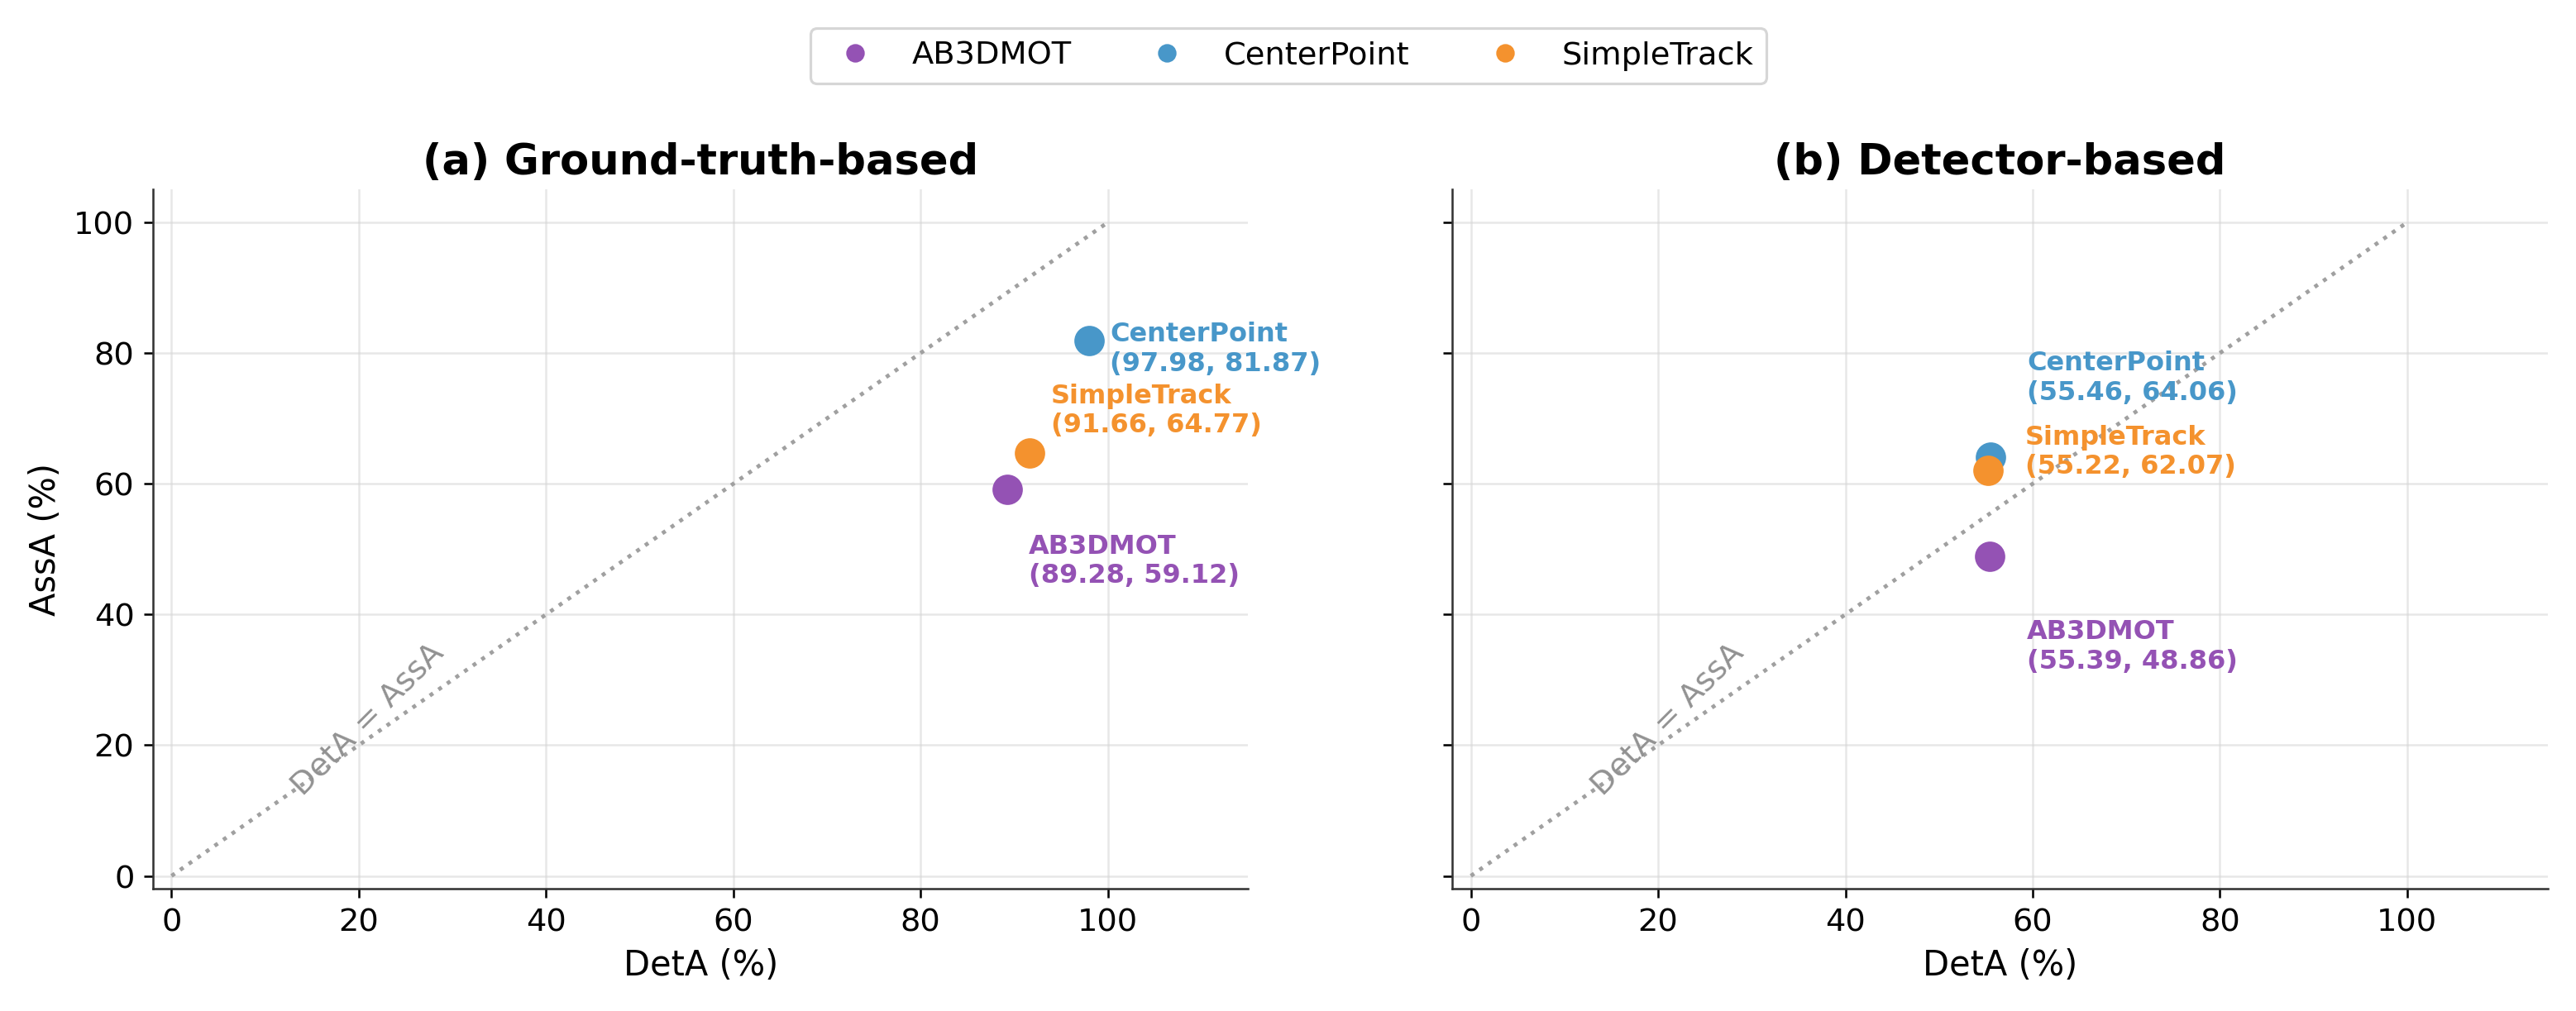

In [7]:
components = overall[["DetA", "AssA", "HOTA"]].copy()
display(components.round(4))
show_figure("aghri_3d_tracking_detection_association_components_new.png")

## Computational performance

Tracker-update throughput is total processed frames divided by tracker-side update time, excluding detector inference. The paper reports it in units of $10^4$ updates/s. MOTA in the plot is the six-sequence equal mean. Throughput and accuracy have different aggregation rules, so they are read from the same saved summary row rather than averaged from two camera or scene summaries.


Throughput (×10⁴ updates/s)  Mean MOTA
Input setting      Tracker                                            
Ground-truth-based AB3DMOT                           0.2297     0.9399
                   CenterPoint                       1.7485     0.9758
                   SimpleTrack                       0.2098     0.9661
Detector-based     AB3DMOT                           0.2457     0.8510
                   CenterPoint                       1.7785     0.8709
                   SimpleTrack                       0.2324     0.8550

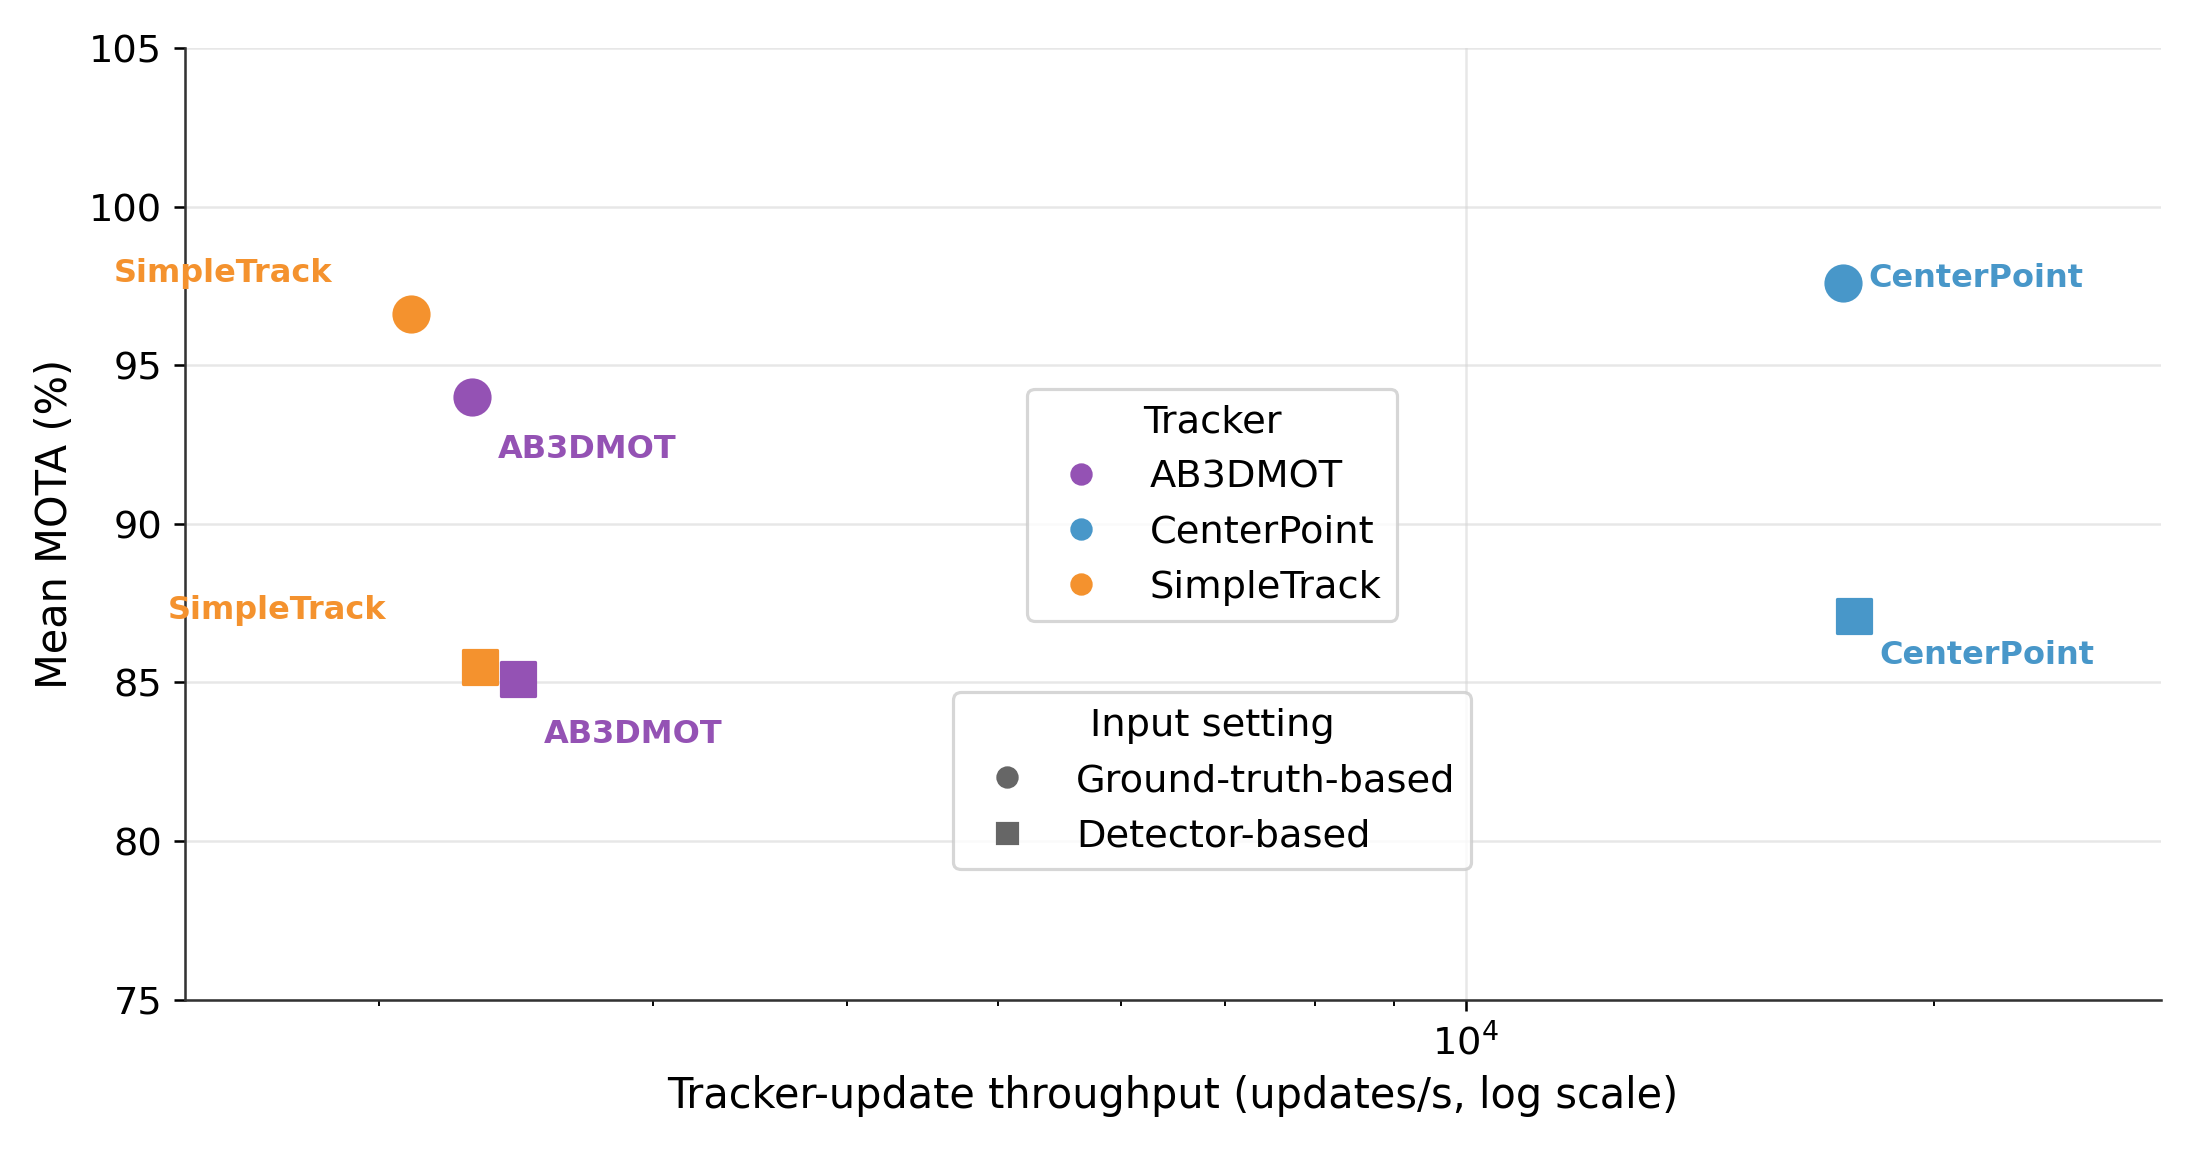

In [8]:
throughput = macro[["source", "tracker", "tracker_fps", "mota"]].copy()
throughput["Input setting"] = throughput.source.map(INPUTS)
throughput["Tracker"] = throughput.tracker.map(TRACKERS)
throughput["Throughput (×10⁴ updates/s)"] = throughput.tracker_fps / 10_000
throughput["Mean MOTA"] = throughput.mota
throughput = throughput[["Input setting", "Tracker", "Throughput (×10⁴ updates/s)", "Mean MOTA"]]
throughput = throughput.set_index(["Input setting", "Tracker"]).reindex(overall.index)
display(throughput.round(4))
assert round(throughput.loc[("Ground-truth-based", "CenterPoint"), "Throughput (×10⁴ updates/s)"], 4) == 1.7485
assert round(throughput.loc[("Detector-based", "CenterPoint"), "Throughput (×10⁴ updates/s)"], 4) == 1.7785
show_figure("aghri_3d_tracking_throughput_vs_mota_new.png")

The six-sequence results show the highest MOTA, IDF1, and HOTA for CenterPoint under both input settings. The lower detector-based scores show the effect of replacing annotated boxes with PointPillars detections. Identity consistency remains difficult in some sequences even with ground-truth boxes.